# DX 603: Project Milestone Two: Modeling and Feature Engineering

### Due: Sunday July 26 @ 11:59PM (with grace period of 2 hours & 1 minute)

### Overview

In Milestone 1, you explored the Zillow dataset, cleaned the data, and developed hypotheses about how preprocessing and feature engineering might improve predictive performance.

In this milestone, you will  develop, evaluate, and refine several machine learning models using those ideas. Rather than simply searching for the best algorithm, you will follow an iterative modeling workflow by:

1. Establishing baseline performance using several regression models.
2. Testing the preprocessing and feature engineering ideas proposed in Milestone 1.
3. Refining the feature set through feature selection.
4. Optimizing model performance through hyperparameter tuning.
5. Comparing the evolution of your models and selecting a final model to evaluate on the held-out test set.

Throughout this milestone, use **repeated 5-fold cross-validation (5 repeats)** to guide your modeling decisions. The held-out test set should be used only once, after all modeling decisions have been completed.




In [1]:
# ===================================
# Useful Imports: Add more as needed
# ===================================

# Standard Libraries
import os
import time
import math
import io
import zipfile
import requests
from urllib.parse import urlparse
from itertools import chain, combinations

# Data Science Libraries
import numpy as np
import pandas as pd
import seaborn as sns

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as mticker  # Optional: Format y-axis labels as dollars
import seaborn as sns

# Scikit-learn (Machine Learning)
from sklearn.model_selection import (
    train_test_split, 
    cross_val_score, 
    GridSearchCV, 
    RandomizedSearchCV, 
    RepeatedKFold
)
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.feature_selection import SequentialFeatureSelector, f_regression, SelectKBest
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, HistGradientBoostingRegressor

# Progress Tracking

from tqdm import tqdm

# =============================
# Global Variables
# =============================
random_state = 42

# =============================
# Utility Functions
# =============================

# Format y-axis labels as dollars with commas (optional)
def dollar_format(x, pos):
    return f'${x:,.0f}'

# Convert seconds to HH:MM:SS format
def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))



## Prelude: Load Your Preprocessed Dataset from Milestone 1

In Milestone 1, you cleaned the Zillow dataset by removing unsuitable features, handling missing values, and encoding categorical variables. In this milestone, you will build, compare, and improve several regression models using that prepared dataset.

Begin by returning to your Milestone 1 notebook and rerunning your code through Part 3, where your dataset has been completely cleaned and encoded, but before any experimental feature engineering ideas were evaluated. Save this dataset and use it as the starting point for this milestone.

For example:

```python
# In Milestone 1
df_cleaned.to_csv("zillow_cleaned.csv", index=False)
```

```python
# In Milestone 2
df = pd.read_csv("zillow_cleaned.csv")
```

Next:

1. Separate the predictors (`X`) from the target (`y`).
2. Split the dataset into training and test sets using `train_test_split`.

Some regression models, such as **Ridge Regression** and **Lasso Regression**, require feature scaling. If you use one of these models, standardize the predictor variables **using only the training data**, then apply the same transformation to the test data.

```python
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
```

**Notes**

- Ordinary Linear Regression, Decision Trees, Random Forests, and HistGradientBoosting do **not** require feature scaling.
- If you create additional features later in this milestone and are using a scaled model, repeat the scaling step so the new features are transformed consistently.
- Throughout this milestone, use the same training/test split so that all models are evaluated on identical data.

In [2]:
# Add as many cells as you need

X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv").squeeze("columns")
y_test = pd.read_csv("y_test.csv").squeeze("columns")
print("Loaded:", X_train.shape, X_test.shape)

# --- Finish encoding three columns Part 3.F left non-numeric ---
# Milestone 1's 3.F only one-hot encoded 5 columns. Three columns are still
# text/boolean and would cause every model to error, so encode

def finalize_encoding(X_tr, X_te):
    X_tr, X_te = X_tr.copy(), X_te.copy()

    # (1) hashottuborspa is boolean True/False - integer 1/0
    X_tr['hashottuborspa'] = X_tr['hashottuborspa'].astype(int)
    X_te['hashottuborspa'] = X_te['hashottuborspa'].astype(int)

    # (2) propertycountylandusecode (69 categories) and propertyzoningdesc
    #     (1,793 categories) are high-cardinality text. One-hot encoding would
    #     add ~1,800 columns, so we frequency-encode: replace each category with
    #     how often it appears in TRAINING data. Frequencies are learned on the
    #     training set only and applied to both sets (unseen test categories - 0).
    for col in ['propertycountylandusecode', 'propertyzoningdesc']:
        freq = X_tr[col].value_counts(normalize=True)
        X_tr[col] = X_tr[col].map(freq).astype(float)
        X_te[col] = X_te[col].map(freq).fillna(0.0).astype(float)

    return X_tr, X_te

X_train, X_test = finalize_encoding(X_train, X_test)
assert X_train.select_dtypes(exclude=[np.number]).shape[1] == 0, "still non-numeric!"
print(f"All numeric now. Final X_train: {X_train.shape}")


Loaded: (61953, 611) (15489, 611)
All numeric now. Final X_train: (61953, 611)


## Problem 1: Model Selection and Baselines [6 pts]

### 1.A Coding

Select **three** regression models from the following list and evaluate each one using the cleaned training dataset.

Use the default hyperparameters provided by scikit-learn (except where scaling is required).

Available models:

* Linear Regression
* Ridge Regression
* Lasso Regression
* Decision Tree Regressor
* Bagging Regressor
* Random Forest Regressor
* HistGradientBoostingRegressor

For each of the three models you choose:

* Train using the **training dataset only**.
* Use **Repeated 5-Fold Cross-Validation** (5 repeats).
* Report validation performance:

  * Mean CV MAE
  * Standard Deviation of CV MAE

Ridge (scaled)          CV MAE =    219,751 ± 2,967   Train MAE =    216,065
Random Forest           CV MAE =    203,285 ± 3,303   Train MAE =     83,492
HistGradientBoosting    CV MAE =    192,694 ± 2,941   Train MAE =    177,750

=== Baseline summary ===
               Model  CV MAE (mean)  CV MAE (std)     Train MAE
      Ridge (scaled)  219750.652129   2967.348663 216065.332105
       Random Forest  203284.780318   3302.788306  83491.909203
HistGradientBoosting  192694.210938   2941.115332 177749.804625


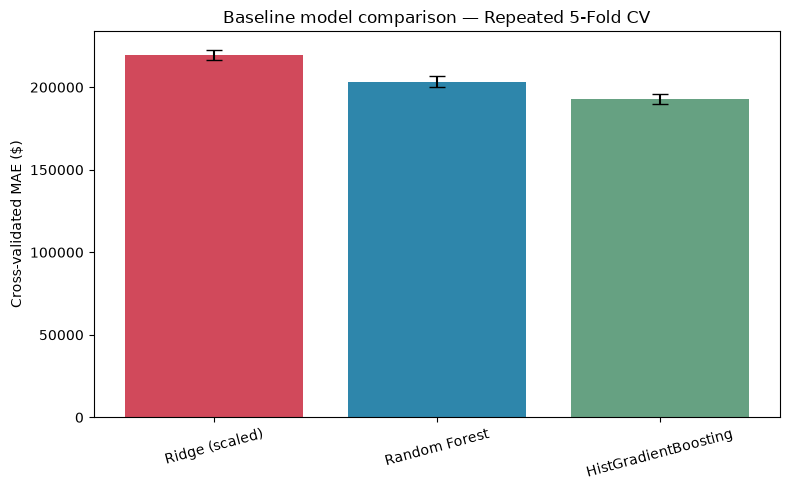

In [ ]:
# Add as many code cells as needed.

# ============================================================
# PROBLEM 1.A — Three baseline models, Repeated 5-Fold CV
# ============================================================
from sklearn.model_selection import cross_val_score, RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

# One model from each family for a meaningful comparison:
#   - Ridge: linear baseline (needs scaling; Ridge over plain LinearRegression
#     because 611 columns with one-hot + redundant features are collinear,
#     and L2 regularization keeps the solution stable).
#   - Random Forest: bagged trees, captures nonlinearity and interactions.
#   - HistGradientBoosting: boosted trees, fast and usually strong on tabular data.
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)

models = {
    'Ridge (scaled)':       make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=42)),
    'Random Forest':        RandomForestRegressor(n_estimators=5, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
}

results = []
for name, model in models.items():
    # Repeated 5-fold CV MAE (25 fits). scoring is negative MAE, so we negate.
    cv_mae = -cross_val_score(model, X_train, y_train,
                              scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1)
    # Training MAE (fit on all training data, predict on it) for the overfit check.
    model.fit(X_train, y_train)
    train_mae = mean_absolute_error(y_train, model.predict(X_train))
    results.append({'Model': name,
                    'CV MAE (mean)': cv_mae.mean(),
                    'CV MAE (std)':  cv_mae.std(),
                    'Train MAE':     train_mae})
    print(f"{name:22s}  CV MAE = {cv_mae.mean():>10,.0f} ± {cv_mae.std():,.0f}   "
          f"Train MAE = {train_mae:>10,.0f}")

results_df = pd.DataFrame(results)
print("\n=== Baseline summary ===")
print(results_df.to_string(index=False))

# Bar chart: CV MAE with std error bars
plt.figure(figsize=(8, 5))
plt.bar(results_df['Model'], results_df['CV MAE (mean)'],
        yerr=results_df['CV MAE (std)'], capsize=6, color=['#d1495b', '#2e86ab', '#66a182'])
plt.ylabel('Cross-validated MAE ($)')
plt.title('Baseline model comparison — Repeated 5-Fold CV')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

### 1.B Discussion

Answer the following questions.

#### 1.B.1

Which of your three models achieved the **lowest validation MAE score **?

> Replace this text with your answer.

#### 1.B.2

Which model produced the **smallest standard deviation** across the repeated cross-validation runs? What does this suggest about its stability?

> Replace this text with your answer.

#### 1.B.3

Did any model appear to overfit or underfit? Explain your reasoning using the training and cross-validation results.

> Replace this text with your answer.

#### 1.B.4

Compare the overall strengths and weaknesses of the three models. Did any model consistently perform better, or were there important tradeoffs between accuracy and stability?

> Replace this text with your answer.

## Part 2: Evaluate Your Feature Engineering Hypotheses [6 pts]

### 2.A Coding

In **Milestone 1**, you proposed several preprocessing and feature engineering ideas that you believed might improve predictive performance.

Select **at least three** of those ideas and evaluate them.

These may include, for example:

* Creating new features
* Transforming existing features
* Removing features
* Combining features
* Other preprocessing ideas that you proposed in Milestone 1

For each idea:

* Apply the preprocessing or feature engineering to the **training dataset only**.
* Retrain the same three baseline models from **Problem 1** using repeated 5-fold cross-validation (5 repeats). 
* Compare the validation performance (mean CV MAE) and stability (standard deviation of CV MAE) with your original baseline results


> One of the most important things you can learn is that **not every clever idea results in an improvement**--they have to be evaluated by careful experiment.  And negative results are valuable if they are carefully evaluated and discussed!

In [ ]:
# Add as many code cells as needed.

### 2.B Discussion

Answer the following questions.

#### 2.B.1

Which of your feature engineering ideas produced the largest improvement in validation performance?

> Replace this text with your answer.

#### 2.B.2

Were any of your ideas unsuccessful or did they reduce model performance? Briefly explain.

> Replace this text with your answer.

#### 2.B.3

Did some models benefit more from feature engineering than others? If so, why do you think this occurred?

> Replace this text with your answer.

#### 2.B.4

Which preprocessing or feature engineering changes will you keep for the remainder of the milestone? Briefly justify your decision.

> Replace this text with your answer.

## Part 3: Refine the Feature Set [6 pts]

### 3.A Coding

Using your dataset after completing **Part 2** (including any preprocessing and feature engineering changes you decided to keep):

Investigate whether **feature selection** can further improve model performance.

You may use one or more of the following methods:

* Forward Selection (for linear regression models)
* Backward Selection (for linear regression models)
* Feature importance from tree-based models (for decision trees, Random Forests, Bagging, and HistGradientBoosting)
* Another reasonable feature selection method

For each of your three models:

* Select a subset of features using an appropriate feature selection method.
* Retrain the model using only the selected features.
* Evaluate the model using the same repeated cross-validation procedure as before.
* Report the validation performance (the mean and standard deviation of the CV MAE).

> Not every model will necessarily benefit from feature selection. Choose methods that are appropriate for the models you selected. Negative results are valuable if they are carefully evaluated and discussed!

In [3]:
# Add as many code cells as needed.

cv_strategy = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)

def evaluate_selected_features(model_name, model, X, y, cv):
    print(f"--- {model_name} ---")
    print(f"Features selected: {X.shape[1]}")
    
    cv_scores = -cross_val_score(model, X, y, scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1)
    
    mean_mae = cv_scores.mean()
    std_mae = cv_scores.std()
    
    print(f"Validation Performance -> Mean CV MAE: {mean_mae:,.0f} ± {std_mae:,.0f}\n")
    return mean_mae, std_mae

In [6]:
# Select the top 50 features with the highest F-statistic value against the target
from sklearn.pipeline import make_pipeline

linear_selector = SelectKBest(score_func=f_regression, k=50)
X_train_ridge = linear_selector.fit_transform(X_train, y_train)
ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=42))

ridge_mean, ridge_std = evaluate_selected_features(
    model_name="Ridge Regression (Scaled)", 
    model=ridge_model, 
    X=X_train_ridge, 
    y=y_train, 
    cv=cv_strategy
)

--- Ridge Regression (Scaled) ---
Features selected: 50
Validation Performance -> Mean CV MAE: 228,563 ± 2,953



In [12]:
from sklearn.feature_selection import SelectFromModel

# 1. Select a subset of features using an appropriate feature selection method (Embedded Method)
# We train a fast, shallow forest specifically to find feature importances
importance_estimator = RandomForestRegressor(n_estimators=30, max_depth=10, random_state=42, n_jobs=-1)
importance_estimator.fit(X_train, y_train)

tree_selector = SelectFromModel(importance_estimator, prefit=True, threshold='mean')
X_train_rf = tree_selector.transform(X_train)
rf_model = RandomForestRegressor(n_estimators=20, random_state=42, n_jobs=-1)

# 3 & 4. Retrain, Evaluate, and Report using our custom method
rf_mean, rf_std = evaluate_selected_features(
    model_name="Random Forest Regressor", 
    model=rf_model, 
    X=X_train_rf, 
    y=y_train, 
    cv=cv_strategy
)

/usr/local/python/3.12.1/lib/python3.12/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


--- Random Forest Regressor ---
Features selected: 35
Validation Performance -> Mean CV MAE: 193,125 ± 3,039



In [13]:
# =====================================================================
# CELL 4: Feature Selection and Evaluation for HistGradientBoosting
# =====================================================================

# 1. Select a subset of features using an appropriate feature selection method
# We reuse the high-quality non-linear features identified by the Random Forest selector

X_train_hgb = X_train_rf.copy()
hgb_model = HistGradientBoostingRegressor(random_state=42)

# 3 & 4. Retrain, Evaluate, and Report using our custom method
hgb_mean, hgb_std = evaluate_selected_features(
    model_name="HistGradientBoosting Regressor", 
    model=hgb_model, 
    X=X_train_hgb, 
    y=y_train, 
    cv=cv_strategy
)

--- HistGradientBoosting Regressor ---
Features selected: 35
Validation Performance -> Mean CV MAE: 193,142 ± 2,825



In [20]:

feature_names = X_train.columns

ridge_mask = linear_selector.get_support()
ridge_features = feature_names[ridge_mask]

tree_mask = tree_selector.get_support()
tree_features = feature_names[tree_mask]

retained_features = set(ridge_features).intersection(set(tree_features))
removed_features = set(feature_names) - set(ridge_features).union(set(tree_features))

print("================ FEATURE SELECTION AUDIT ================\n")
print(f"Total features evaluated: {len(feature_names)}")
print(f"Features kept by Ridge (Linear): {len(ridge_features)}")
print(f"Features kept by Random Forest / Hist Gradient (Non-Linear): {len(tree_features)}")

print(f"\n--- Consistently Retained Features ({len(retained_features)}) ---")
# print(sorted(list(retained_features)))
for index, feature in enumerate(sorted(retained_features), start=1):
    print(f"{feature}")

print(f"\n--- Consistently Removed Features ({len(removed_features)}) ---")
print(f"A total of {len(removed_features)} features were completely discarded by both selectors.")

# Reserving this code for Part 2 completion
# engineered_hypotheses = [
#     'hashottuborspa', 
#     'propertycountylandusecode', 
#     'propertyzoningdesc'
# ]

# print("\n--- Milestone 1 Engineered Feature Audit ---")
# for col in engineered_hypotheses:
#     in_ridge = col in ridge_features
#     in_tree = col in tree_features
    
#     if in_ridge or in_tree:
#         retained_by = []
#         if in_ridge: retained_by.append("Ridge")
#         if in_tree: retained_by.append("Tree")
#         print(f"{col} was retained by: {' and '.join(retained_by)}")
#     else:
#         print(f"{col} was completely dropped.")

================ FEATURE SELECTION AUDIT ================

Total features evaluated: 611
Features kept by Ridge (Linear): 50
Features kept by Random Forest / Hist Gradient (Non-Linear): 35

--- Consistently Retained Features (26) ---
bathroomcnt
bedroomcnt
buildingqualitytypeid
calculatedfinishedsquarefeet
fullbathcnt
garagetotalsqft
latitude
propertycountylandusecode
regionidcity_10389.0
regionidcity_12520.0
regionidcity_19177.0
regionidcity_26964.0
regionidcity_29712.0
regionidcity_40009.0
regionidcity_52842.0
regionidcity_53571.0
regionidzip_96030.0
regionidzip_96050.0
regionidzip_96058.0
regionidzip_96086.0
regionidzip_96116.0
regionidzip_96117.0
regionidzip_96120.0
regionidzip_96969.0
regionidzip_96975.0
yearbuilt

--- Consistently Removed Features (552) ---
A total of 552 features were completely discarded by both selectors.


### 3.B Discussion

#### 3.B.1

Did feature selection improve the validation performance of any of your models?

> Replace this text with your answer.

#### 3.B.2

Were there features that were consistently retained (or consistently removed) across multiple models?

> Replace this text with your answer.

#### 3.B.3

Were any of your engineered features selected as important? If so, what does this suggest about the hypotheses you developed in Milestone 1?

> Replace this text with your answer.

#### 3.B.4

After feature selection, did simpler models perform as well as—or better than—the models using the full feature set? Briefly discuss any tradeoffs you observed between model complexity and predictive performance.

> Replace this text with your answer.

> Your text here

## Part 4: Tune Your Models [8 pts]

### 4.A Coding

Using the three models developed in **Part 3** (including your final preprocessing, feature engineering, and feature selection decisions):

Investigate whether **hyperparameter tuning** can further improve model performance.

For each of your three models:

* Select one or more important hyperparameters to tune.
* Use one or more appropriate tuning methods. Consider first using validation curves (`sweep_parameter`) to identify a promising region or performance plateau, followed by a focused search using methods such as:

    * GridSearchCV
    * RandomizedSearchCV
    * Another reasonable hyperparameter search method

* Choose hyperparameter values based on the validation results. If several nearby values produce similar validation performance (a performance plateau), prefer **values near the beginning of the plateau,** since they often produce simpler models with nearly identical predictive performance.
* Retrain the model using those hyperparameters.
* Evaluate the tuned model using repeated 5-fold cross-validation (5 repeats). 
* Report the validation performance (**mean** and **standard deviation** of the CV MAE).


In [ ]:
# Add as many code cells as needed.

### 4.B Discussion

Answer the following questions.

#### 4.B.1

Which hyperparameters had the greatest impact on model performance? Briefly explain.

> Replace this text with your answer.

#### 4.B.2

Did hyperparameter tuning substantially improve the performance of all three models, or only some of them?

> Replace this text with your answer.

#### 4.B.3

Which tuning method(s) did you use for each model? Briefly explain why you chose those methods.

> Replace this text with your answer.

#### 4.B.4

After tuning, how did the relative performance of your three models change? Did tuning affect which model appeared to perform best?

> Replace this text with your answer.

## Part 5: Final Model and Workflow Assessment [14 pts]

### 5.A Coding

Using the work completed in **Parts 1–4**:

Select your **best-performing model** and prepare your final modeling pipeline.

Your pipeline should include all preprocessing, feature engineering, feature selection, and hyperparameter tuning decisions that you chose to retain.

Evaluate your final model by:

* Training on the complete training dataset.
* Reporting the **mean** and **standard deviation** of the repeated cross-validation MAE.
* Evaluating the model on the held-out test set.
* Reporting the final test MAE.

In [ ]:
# Add as many code cells as needed.

### 5.B Discussion

Answer the following questions.

#### 5.B.1

Compare the performance of your final model with its original baseline from **Part 1**. Which changes contributed the most to the improvement?

> Replace this text with your answer.

#### 5.B.2

Looking back at the hypotheses you proposed in **Milestone 1**, which were supported by your experimental results? Were any hypotheses disproved?

> Replace this text with your answer.

#### 5.B.3

Why did you select this model as your final model? Discuss both its predictive performance and any other considerations (such as stability, simplicity, or interpretability).

> Replace this text with your answer.

#### 5.B.4

What did you learn about your dataset and the machine learning process through this end-to-end modeling workflow? If you had additional time, what would you investigate next?

> Replace this text with your answer.